# Quantum Computing Laboratory Activity 1

This lab combines foundational quantum computing principles, a guided walkthrough of single-qubit gates in Qiskit, Bloch-sphere visualization, and hands-on exercises/challenges for you to complete.

$\newcommand{\bra}[1]{\langle#1|}$
$\newcommand{\ket}[1]{|#1\rangle}$

## Introduction

### Basic Principles of Quantum Computing

Classical computers store and process information as **bits** — each one is definitely a 0 or a 1. Quantum computers use **qubits**, which follow the rules of quantum mechanics instead. Four ideas from that framework matter for this lab:

**1. Superposition.** A qubit's state isn't limited to |0⟩ or |1⟩ — it can be a weighted combination of both at once:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1$$

$\alpha$ and $\beta$ are **complex amplitudes**. You can't observe them directly; you only ever get one classical answer out of a measurement.

**2. Measurement.** Measuring a qubit forces it to "pick" a definite outcome: 0 with probability $|\alpha|^2$, or 1 with probability $|\beta|^2$. This is irreversible — the superposition **collapses**, and the original amplitudes are gone. This is why a single measurement tells you very little; the code below runs each circuit **1024 times ("shots")** and plots a histogram of outcomes to estimate the underlying probabilities.

**3. Phase.** $\alpha$ and $\beta$ are complex numbers, so they carry both a *magnitude* (which sets measurement probability) and a *phase* (angle). Two states can have identical measurement probabilities but different phase — and be physically different. Phase is invisible to a direct measurement, but becomes visible through **interference** when combined with other operations. This distinction — *probability vs. phase* — is the single most important idea in this notebook, and the "Try It Yourself" section at the end is built entirely around it.

**4. Quantum gates.** Just as classical logic gates (AND, OR, NOT) manipulate bits, quantum gates manipulate qubits. Every quantum gate is represented by a **unitary matrix** (a matrix that preserves total probability) and drawn as a box on a **circuit diagram**, which reads left-to-right as a sequence of operations applied to one or more **qubits** (the `q` line) ending in a **measurement** onto classical bits (the `c` line). This lab walks through the single-qubit gates you'll see constantly: X, Y, Z, H, S, and T.

*(A related idea, **entanglement** — correlations between multiple qubits with no classical equivalent — is what gives multi-qubit circuits their real power. It's outside the scope of this single-qubit lab but is the natural next topic once you're comfortable with the gates below.)*

### Quantum Programming

Quantum programming can be understood as consisting of two main components. First, there is an abstract representation known as the circuit model, which is used to describe how quantum computations are performed. In this model, quantum operations are represented as gates that act on qubits and are arranged sequentially to form a quantum circuit.

Second, a practical programming language is used to implement and execute these quantum circuits. In this laboratory, we will use Python, together with the Qiskit framework, to create, manipulate, and run quantum programs.

Before writing code, it is important to understand how quantum circuits represent computational processes. Once the basic ideas behind quantum circuits are introduced, we will proceed to constructing and executing these circuits using Python.

### **Quantum circuits**


At the core of every quantum program is a **quantum circuit**. This concept is similar to circuits used in classical computing. However, instead of wires carrying **classical bits**, the wires in a quantum circuit carry **qubits (quantum bits)**. These qubits are manipulated using **quantum gates**, which perform operations on their quantum states.

A generic quantum circuit can be represented as follows:

<img src="circuit1.png" alt="Quantum circuit" style="width: 300px;"/>

In this diagram, each horizontal line represents a **qubit wire**, and the rectangular blocks represent **quantum gates** acting on the qubits. Gates may operate on one or more qubits, which is why they may have multiple wires entering and leaving the block. The computation proceeds from **left to right**, meaning the quantum state evolves as it passes through each gate in sequence.

For example, in the figure, the circuit begins with a four-qubit initial state given by

$$
\ket{\psi_I} = \ket{0} \otimes \ket{0} \otimes \ket{0} \otimes \ket{0}
\equiv \ket{0000}.
$$

This represents a **product state**, where all four qubits are initialized in the state \( \ket{0} \).

As the quantum state moves through the circuit, the qubits are acted upon by a sequence of quantum gates labeled \(U_1\), \(U_2\), \(U_3\), and \(U_4\). Each gate transforms the state according to a specific quantum operation.

After passing through all gates, the circuit produces a final quantum state

$$
\ket{\psi_F}
$$

which may be an **entangled state**, meaning the qubits are no longer independent but instead share correlations with one another.

Finally, the qubits are **measured in the computational basis**, which converts the quantum information into classical outcomes (0 or 1). In circuit diagrams, this measurement process is typically represented by a symbol resembling a measurement device.

### Summary

A quantum circuit resembles a classical circuit in structure, but the components are fundamentally different. In quantum computing:

- **Classical bits** → **Qubits**
- **Classical logic gates** → **Quantum gates (unitary operations)**
- **Classical readout** → **Quantum measurement**

### **Quantum programming libraries**

With the circuit paradigm underlying quantum programming, our task is now to use a generic programming language to **create** and **run** circuits depicted above. To this aim, many libraries have been created. Among the best known to date are: 

* [`Qiskit` by IBM](https://qiskit.org/) (Python)

* [`Cirq` by Google](https://quantumai.google/cirq) (Python)

* [`Q#` by Microsoft](https://azure.microsoft.com/en-us/resources/development-kit/quantum-computing/)

There are others too. However, because `Qiskit`, which was one of the first, enjoys wide support among quantum hardware vendors and is used widely in education, we will focus on `Qiskit` in our practice session. Since many other libraries also rely on the circuit model, once one masters `Qiskit`, it is relatively easy to learn and use a different library.

## Setup

### Install Qiskit (Run once)

In [1]:
# NOTE on a dependency trap: this environment has an old `contourpy` (a
# matplotlib dependency) that pins numpy<2.0. qiskit 2.x requires numpy>=2.0.
# Installing matplotlib and qiskit separately lets pip quietly satisfy
# matplotlib using the old contourpy, which drags numpy back below 2.0 and
# breaks qiskit's transpile() with "ValueError: NoneType copy mode not
# allowed." Installing everything together, with numpy and contourpy pinned
# to numpy-2-compatible versions, avoids that.
!pip install -U "numpy>=2.0,<2.8" "contourpy>=1.3" "matplotlib>=3.9" qiskit qiskit-aer pylatexenc charset_normalizer

### Import Libraries

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram, plot_bloch_vector, plot_bloch_multivector
import numpy as np

### Create Simulator

In [3]:
simulator = Aer.get_backend('aer_simulator')

## **Practice session 1: Single qubit**

### **First circuit: template of a quantum program**

The basic template of a quantum program contains two parts: 

1. create and design a circuit
2. run the circuit.

The following code shows this structure.

In [4]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

# create quantum circuit
qc = QuantumCircuit(1)

qc.x(0)          # apply X gate
qc.measure_all() # measure qubit

# draw the circuit
print(qc.draw())


        ┌───┐ ░ ┌─┐
     q: ┤ X ├─░─┤M├
        └───┘ ░ └╥┘
meas: 1/═════════╩═
                 0 


{'1': 1024}


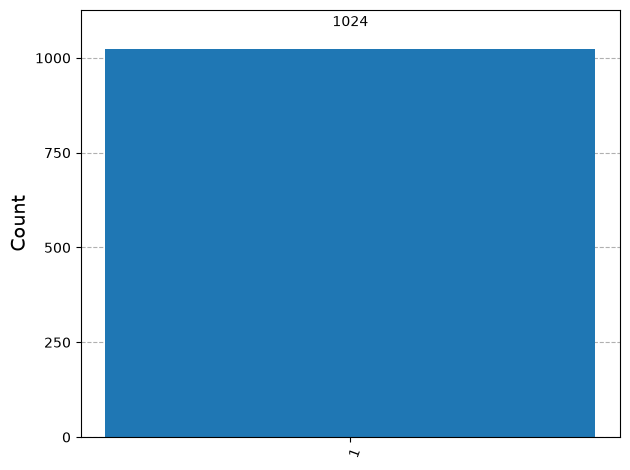

In [5]:
# run simulation
sim = Aer.get_backend('aer_simulator')
result = sim.run(qc).result()

# get counts
counts = result.get_counts()

print(counts)
plot_histogram(counts)

Let us walk through the code. 

In line 5 (L5) we create a quantum circuit `qc` that consists of 1 qubit, the argument of `QuantumCircuit()`. At this point, the circuit is an empty object, a container to which we can add gates. 

In L7 we add the Pauli $X$ gate `x(qubit)`, which flips the qubit state. The argument `0` is the number of the qubit to which the gate is applied.

When we are done with unitary gates, we add a measurement gate at the end of the circuit in L8. This performs a measurement in the computational basis, the basis $\{ \ket{0}, \ket{1} \}$. 

This concludes our simple circuit.

To run the circuit (L11-L13), we create a 'quantum machine' on which the circuit will be run. The library allows one to choose between different kinds of 'quantum machines'. It can be a fake 'quantum machine', that is, a simulator, which is basically a classical computer with a CPU or GPU that simulates a quantum computer. Or it can be a real quantum device that is implemented in a particular physical hardware. At this point, we have chosen the `aer_simulator` which is simulator that can be mimic many different kinds of quantum evolutions.

Finally, in L16 we extract measurement statistics from results.

What does the printout `{'1': 1024}` show? It shows that as a result of the measurement, we have gotten the state $\ket{1}$ 1024 times. By default, our simulator ran the circuit 1024 times, and each time we got the same state.

We can depict this in a histogram. The histogram shows probabilities instead of raw counts.

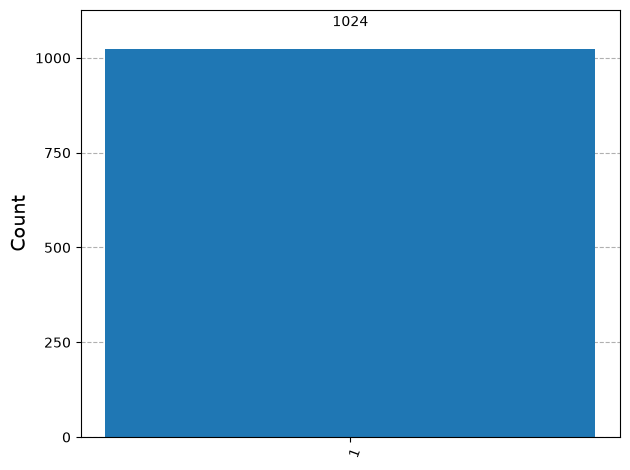

In [6]:
plot_histogram(counts)

We can also draw the quantum circuit. The argument `"mpl"` gives a nice matplotlib output.

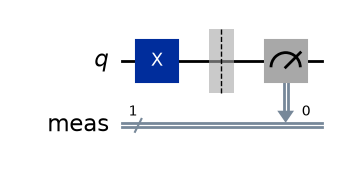

In [7]:
qc.draw("mpl")

The line or wire marked with `q` depicts our qubit. The dashed line is a barrier that visually separates different operations; it is more useful with larger circuits and measurements.

At the end there is the measurement.

Note that the circuit has an additional wire `meas` that we did not add. When we measure, we need to store the measurement result somewhere; for this purpose, the library has added a classical bit silently. We could have, and will add, classical bits explicitly in the future.

Note also that the result of the computation depends on the initial state. By default the initial state is set to $\ket{0}$. If we want, we can set the initial state to whatever we like. We can also draw the circuit with the initial state of the qubit(s) and the classical bit(s) shown explicitly, here $\ket{0}$ and $0$, respectively.

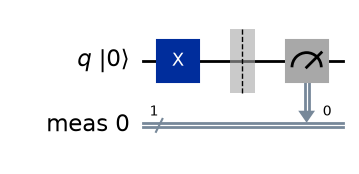

In [8]:
qc.draw(output="mpl", initial_state=True)

> **Exercise 1**. Display the circuit using a text backend by setting output to `"text"`.

### **Measurement**

Measurement is a central to quantum theory. When we want to learn what is the state of the quantum system we need to carry out a measurement. For quantum computing it means if we want to learn what is the result of the computation, we need to carry out a measurement on the qubits that comprise our quantum computer. Let us investigate measurement.

In the above histogram we learned that measurement of the qubit gave the state $\ket{1}$ for all runs of the circuit. This means the probability of getting $\ket{1}$ was 100%. In fact, this is exactly what we would get in classical setting: if the initial bit is $0$ and we perform a NOT operation, the output is $1$.

Let us next set the initial state $\ket{\psi_i}$ to a linear combination or superposition of basis qubits

$$
\ket{\psi_i} = \frac{\ket{0} + \ket{1}}{\sqrt{2}}.
$$

This corresponds to the vector $\left(1 / \sqrt{2}, 1 / \sqrt{2}\right)$. Let us see how the result changes.

        ┌─────────────────────────────┐┌───┐ ░ ┌─┐
     q: ┤ Initialize(0.70711,0.70711) ├┤ X ├─░─┤M├
        └─────────────────────────────┘└───┘ ░ └╥┘
meas: 1/════════════════════════════════════════╩═
                                                0 

Counts = {'1': 520, '0': 504}


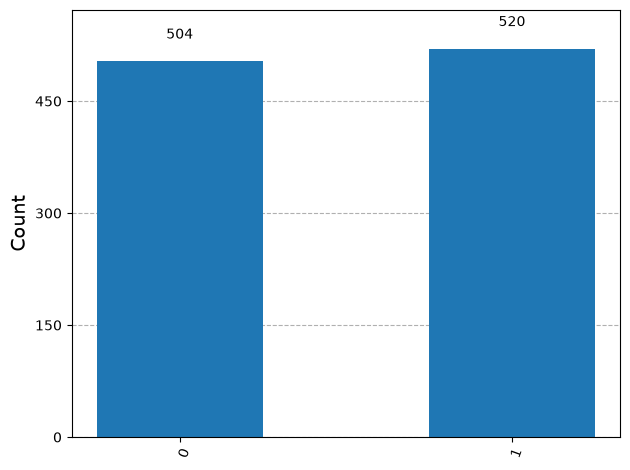

In [9]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
import numpy as np

# create quantum circuit
qc = QuantumCircuit(1)

# define initial state (superposition)
init_state = [1/np.sqrt(2), 1/np.sqrt(2)]

# initialize qubit
qc.initialize(init_state, 0)

# apply X gate
qc.x(0)

# measure
qc.measure_all()

# draw circuit
print(qc.draw())

# run simulation
sim = Aer.get_backend('aer_simulator')
result = sim.run(qc).result()

# get results
counts = result.get_counts()

print("\nCounts =", counts)

# plot histogram
plot_histogram(counts)


We observe that the states $\ket{0}$ (represented by `0`) and $\ket{1}$ (represented by `1`) were obtained in an almost equal number of cases. The histogram shows the respective probabilities, that is, the relative number of occurrence of each outcome, $p_i = \frac{N_i}{N}$ where $N_i$ is the number of outcomes $i$ and $N$ is the total number of outcomes.

We know from quantum theory that the square moduli of coefficients in the state vector show probabilities. The state vector in the code has $1/\sqrt{2}$ for each state and the $X$ gate flips both qubits, giving the same state. Hence the probability of getting each should be $0.5$, and not less and not more. But when you run the above circuit many times, you see that the distribution is always different and rarely precisely $(0.5, 0.5)$. What is happening?

The reason is that the simulator is trying to mimic a realistic quantum machine. An experimental distribution above generally differs from the ideal distribution $(0.5, 0.5)$. We would get closer to the ideal homogeneous distribution $(0.5, 0.5)$ when we increase the number shots. This is the same phenomenon as in any other random experiment like tossing a coin or rolling a die.

In the following exercises, use the code above.

> **Exercise 2.** Experiment with a different initial state in the above code. Set the initial state to `[np.sqrt(1 / 4), np.sqrt(3 / 4)]`. How do the counts and the histogram change? Use a large number of shots to get better statistics.

### **Bloch sphere visualization**

The state $\ket{\psi}$ of a single qubit lives in $\mathbb{C}^2$. The two complex coordinates of this space correspond to four real numbers, that is, a four dimensional real space. We cannot visualize this geometrically. 

However, we can represent the quantum state using a 3D unit vector, the so called Bloch vector. This enables to visualize the quantum state using 3D geometry. It is a great tool for studying the behavior of qubits.

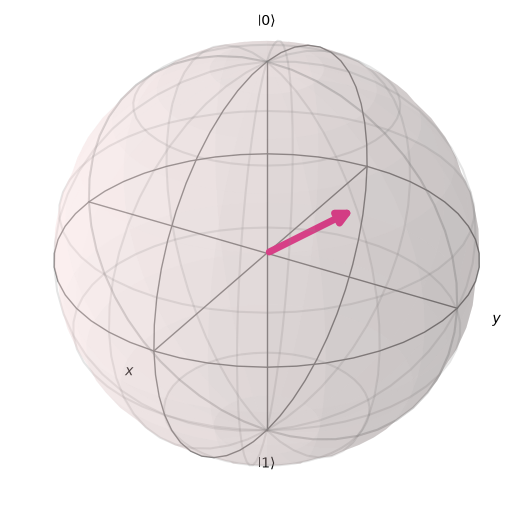

In [3]:
from qiskit.visualization import plot_bloch_vector

vector = [1, 1, 1]         # coordinates [x, y, z]
plot_bloch_vector(vector)  # plot in the Bloch sphere

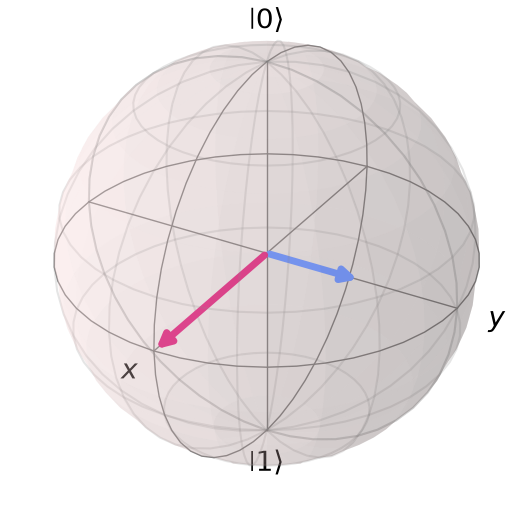

In [6]:
from qiskit.visualization.bloch import Bloch

b = Bloch()

vector1 = [1, 0, 0]
vector2 = [0, 0.5, 0]

b.add_vectors(vector1)
b.add_vectors(vector2)

b.show()

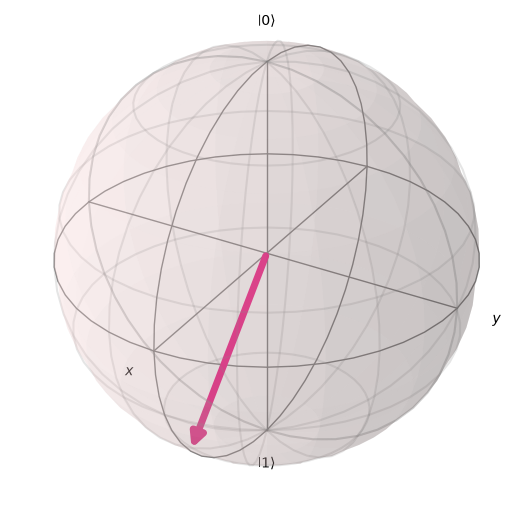

In [7]:
from qiskit.visualization import plot_bloch_vector
import numpy as np

vector = [1/np.sqrt(2), 0, -1/np.sqrt(2)]

plot_bloch_vector(vector)

It is important to keep in mind that the quantum state and the Bloch vector are two different objects. They belong to different spaces. The Bloch vector *represents* the quantum state.

Secondly, the Bloch sphere is first and foremost intended for single qubit states. Although we will sometimes use the Bloch sphere for multi-qubit states, its usage there will be limited.

## Single-Qubit Gates

Single qubit gates are the building blocks of your quantum circuit. When we build quantum circuits, we only need a restricted set of gates&mdash;a universal set&mdash;to build any circuit we want. In more mathematical terms, we can express any unitary (=any circuit) with a series of gates that belong to a universal set.

#### **Pauli gates**

These are the gates represented by the Pauli matrices

$$
X = \begin{bmatrix} 
      0 & 1 \\ 1 & 0 
    \end{bmatrix},\quad\quad\quad\quad 
Y = \begin{bmatrix} 
      0 & -i \\ i & 0 
    \end{bmatrix},\quad\quad\quad\quad 
Z = \begin{bmatrix} 
      1 & 0 \\ 0 & -1 
    \end{bmatrix}.
$$


Using Qiskit, we represent them with the respective lower case letters. Let's build a simple circuit without a measurement.

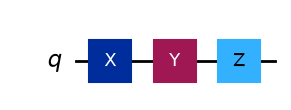

In [11]:
qc = QuantumCircuit(1)
qc.x(0)
qc.y(0)
qc.z(0)
qc.draw("mpl")

### Pauli-X Gate (NOT Gate)

The **X gate** is the quantum analogue of a classical NOT gate: it flips the qubit's computational basis state.

$$X = \begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix}$$

State transformation:

|0⟩ → |1⟩  
|1⟩ → |0⟩

Geometrically, X is a 180° rotation of the qubit's state around the X-axis of the **Bloch sphere** (the standard picture of a single qubit's state as a point on a sphere). Unlike the phase gates you'll meet later (Z, S, T), X changes the qubit's *measurement probabilities* directly and deterministically — starting from a definite |0⟩, you should expect to measure |1⟩ every single time, with no randomness at all. That's what the histogram below should confirm.

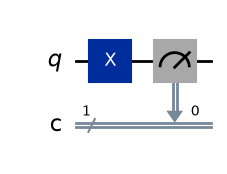

In [12]:
qc = QuantumCircuit(1,1)

qc.x(0)
qc.measure(0,0)

qc.draw('mpl')

{'1': 1024}


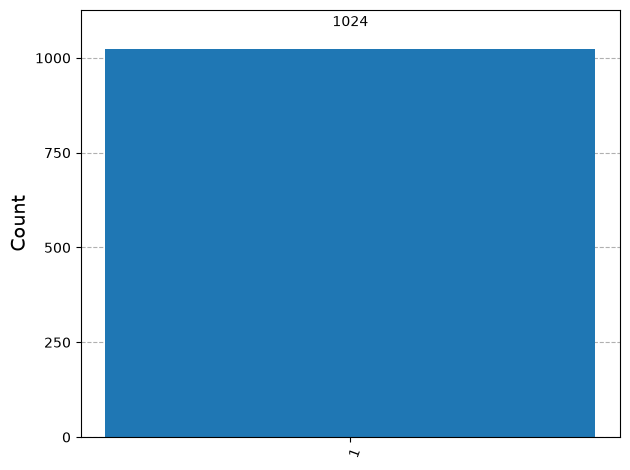

In [13]:
compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()
print(counts)

plot_histogram(counts)

**Bloch sphere view of the X gate**

Let us illustrate the effect of the $X$ gate on the Bloch sphere. In the following example, we do not perform a measurement at the end of the circuit. We will use the simulator that enables to directly inspect the state after running the circuit.

In [14]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector

# create quantum circuit
qc = QuantumCircuit(1)

qc.x(0)                     # apply X gate

# save statevector
qc.save_statevector()

# run simulator
sim = Aer.get_backend('aer_simulator')
result = sim.run(qc).result()

# extract final state
final_state = result.get_statevector(qc)
final_state


Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


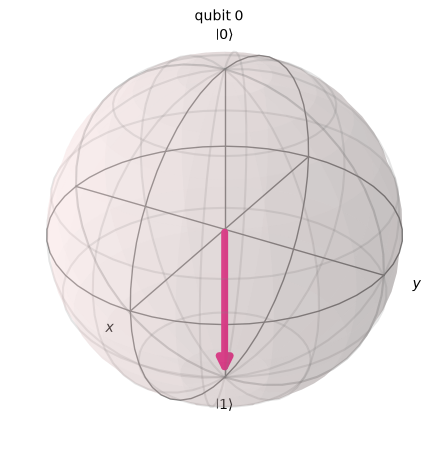

In [15]:
# visualize on Bloch sphere
plot_bloch_multivector(final_state)


Note that

1. we did not specify the initial state, so the initial state was $\ket{0}$,

2. we displayed the quantum state (which lives in $\mathbb{C}^2$) directly on the Bloch sphere using the `plot_bloch_multivector()` routine. Using the latter, we did not need to convert the state into a 3D Bloch vector.

We can think of the $X$ gate as performing a rotation by $\pi$ radians around the $x$-axis on the Bloch sphere. It is often called a NOT-gate in analogy to the classical NOT gate. 

Similarly, we can think of the $Y$ and $Z$ gates as $\pi$ rotations around the $y$- and $z$-axes, respectively.

### Pauli-Y Gate

The **Pauli-Y gate** performs both a **bit flip and a phase flip** simultaneously.  
It is equivalent to applying the **X gate and Z gate together** (up to an overall global phase: $Y = iXZ$).

The matrix representation of the Pauli-Y gate is:

\[
Y =
\begin{bmatrix}
0 & -i \\
i & 0
\end{bmatrix}
\]

State transformation:

|0⟩ → i|1⟩  
|1⟩ → −i|0⟩  

This means the qubit flips like the **X gate** (|0⟩ becomes |1⟩ and vice versa), but each outcome also picks up an extra phase factor ($i$ or $-i$). On the Bloch sphere, Y is a 180° rotation around the Y-axis — the same "flip" geometry as X, just around a different axis.

**Why the measurement result looks identical to X:** even though Y introduces a phase that X doesn't, a measurement only reads off $|\alpha|^2$ and $|\beta|^2$ — and $|i|^2 = |-i|^2 = 1$, same as the plain X case. So starting from |0⟩, X and Y are indistinguishable by measurement counts alone; the difference only shows up if you inspect the amplitudes directly (e.g. with `Statevector`) or combine Y with another gate that's sensitive to phase, the way the T-gate exercises do later.

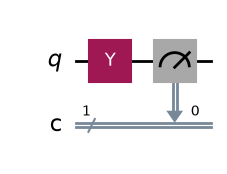

In [16]:
qc = QuantumCircuit(1,1)

qc.y(0)

qc.measure(0,0)

qc.draw('mpl')

{'1': 1024}


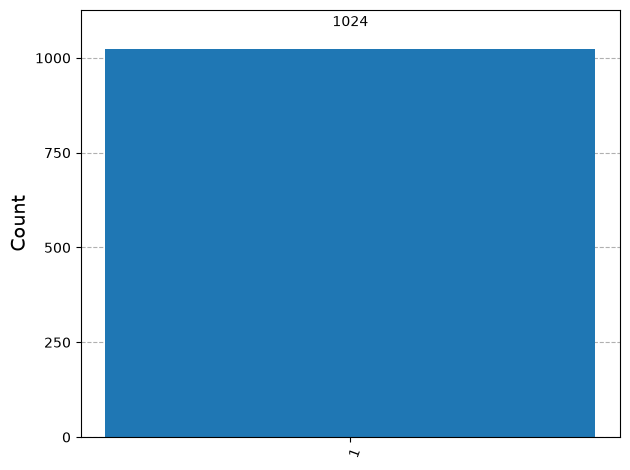

In [17]:
compiled = transpile(qc, simulator)

result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()

print(counts)

plot_histogram(counts)

### Pauli-Z Gate

The **Pauli-Z gate** leaves |0⟩ unchanged and flips the sign (phase) of |1⟩. It completes the trio of Pauli gates (X, Y, Z) referenced above — together, X, Y, and Z correspond to 180° rotations around the three axes of the Bloch sphere.

The matrix representation of the Pauli-Z gate is:

\[
Z =
\begin{bmatrix}
1 & 0 \\
0 & -1
\end{bmatrix}
\]

State transformation:

|0⟩ → |0⟩  
|1⟩ → −|1⟩  

Like the S and T gates below, Z is a **phase-only** gate: it never changes the measurement probabilities of a qubit that starts purely in |0⟩ or |1⟩ — a `-1` in front of an amplitude doesn't change $|{-1}|^2 = 1$. Its effect only becomes visible once the qubit is in **superposition** (created with H below) and later recombined — that's exactly the mechanism explored in the H→T→H exercise at the end of this notebook. This is also why we apply an H *before* Z in the circuit below: measuring Z applied to a plain |0⟩ would just always give 0, telling you nothing new.

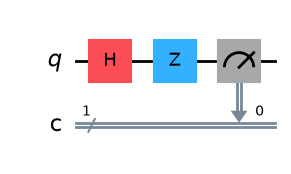

In [18]:
qc = QuantumCircuit(1,1)

qc.h(0)      # create superposition so Z's phase flip has a visible effect later
qc.z(0)
qc.measure(0,0)

qc.draw('mpl')

{'0': 498, '1': 526}


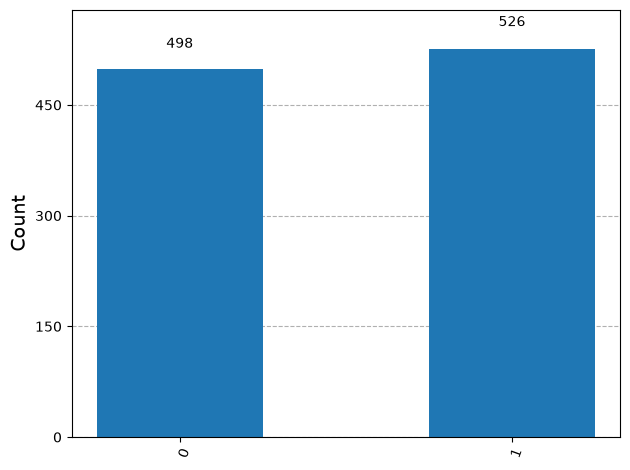

In [19]:
compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()
print(counts)   # ~50/50, same as plain H: Z's phase flip is invisible to a Z-basis measurement here

plot_histogram(counts)

> **Exercise 3**. Visualize the action of the $Z$ gate on the initial state `[1. / np.sqrt(2), 1. / np.sqrt(2)]` using the Bloch sphere. Use the code above.

### Hadamard Gate

The **Hadamard gate (H)** is the workhorse of quantum computing: it takes a definite state and turns it into an **equal superposition**.

$$H = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 & 1 \\ 1 & -1 \end{bmatrix}$$

State transformation:

|0⟩ → (|0⟩ + |1⟩)/√2  
|1⟩ → (|0⟩ − |1⟩)/√2

The $1/\sqrt{2}$ factor exists so the resulting probabilities, $|1/\sqrt{2}|^2 = 1/2$, still sum to 1. Measuring this state gives 0 or 1 with equal 50/50 probability — a coin flip, but a *quantum* one: unlike a classical random bit, the qubit genuinely holds both possibilities at once until measured.

H is also its own inverse ($H \cdot H = I$): applying it twice in a row returns the qubit to where it started. That "undo" property is exactly what makes the H→T→H sandwich in the Try-It-Yourself section work — the second H isn't just "doing superposition again," it's **recombining** the two branches so that any phase picked up in between shows up as a shift in probability. This pattern (superposition → phase gate → un-superposition) is the basic template behind interference-based quantum algorithms.

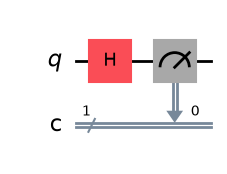

In [20]:
qc = QuantumCircuit(1,1)

qc.h(0)
qc.measure(0,0)

qc.draw('mpl')

{'0': 500, '1': 524}


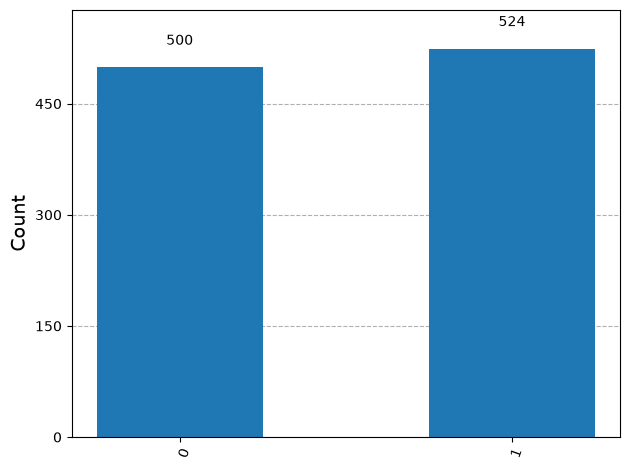

In [21]:
compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()
print(counts)

plot_histogram(counts)

**Bloch sphere view of the Hadamard gate**

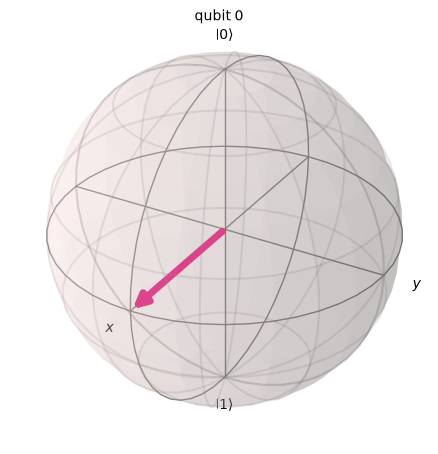

In [22]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector

# create quantum circuit
qc = QuantumCircuit(1)

qc.h(0)                    # apply Hadamard gate
qc.save_statevector()      # save statevector for later

# run
sim = Aer.get_backend('aer_simulator')
result = sim.run(qc).result()

# get statevector
final_state = result.get_statevector()

# visualize
plot_bloch_multivector(final_state)


We can think of the Hadamard gate as a transformation between the $X$ and $Z$ bases. Alternatively, it can be viewed as a rotation around the axis in the direction of the Bloch vector $[1, 0, 1]$.

> **Exercise 4**. Change the above code as follows: perform the Hadamard gate $H$, then the $Z$ gate, followed by one more $H$.

*(This connects directly to the H→T→H exercise near the end of this notebook — same sandwich structure, different phase gate. Compare your result here with that one.)*

### Rotations (Rₓ, R_y, R_z)

Above we mentioned rotations by $\pi$ radians. We can rotate the state by any angle $\phi$ around $x, y$ and $z$-axis using parameterized gates $R_x(\phi), R_y(\phi)$ and $R_z(\phi)$. The Python routines are, respectively, `rx(), ry()` and `rz()` with the arguments `theta, qubit` in each case.

In the following example we rotate $\ket{0}$ around the $x$-axis by $\pi / 2$.

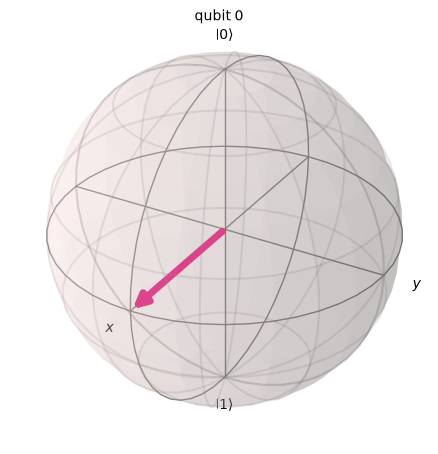

In [23]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector
import numpy as np

# create quantum circuit
qc = QuantumCircuit(1)

qc.ry(np.pi / 2, 0)        # apply Rx rotation
qc.save_statevector()      # save statevector

# run simulator
sim = Aer.get_backend('aer_simulator')
result = sim.run(qc).result()

# extract final quantum state
final_state = result.get_statevector()

# visualize on Bloch sphere
plot_bloch_multivector(final_state)


> **Exercise 5**. Add a rotation to the above code so that the final state is rotated halfway between the $x$ and $y$-axis.

### Phase Gates: P and S

Rotation around the $z$-axis has the form 

$$
Z = \begin{bmatrix} 
      1 & 0 \\ 0 & e^{i\phi} 
    \end{bmatrix}.
$$

and is alternatively called the $P$-gate (=phase gate) since it adds a phase $e^{i\phi}$ to $\ket{1}$. In Python, we write `p(phase, qubit)`.

The $S$-gate is a $z$-rotation by $\pi / 2$ radians, so it's really the $P$-gate with $\phi = \pi / 2$. 

In the following example we use the $P$-gate to rotate the qubit in the positive direction of the $y$-axis.

The **Phase gate (S)** adds a **phase shift of 90°** to the |1⟩ state while leaving |0⟩ unchanged.

The matrix representation of the S gate is:

\[
S =
\begin{bmatrix}
1 & 0 \\
0 & i
\end{bmatrix}
\]

State transformation:

|0⟩ → |0⟩  
|1⟩ → i|1⟩  

Unlike the X gate, the S gate does **not flip the qubit state**.  
Instead, it modifies the **phase of the quantum state**, which becomes important when the qubit is in **superposition**.

Note that $S$ is literally $Z$'s square root: applying S twice equals one Z ($S^2 = Z$), since $i \times i = -1$. This "gates as fractional rotations" pattern reappears with T below, and it's why S is sometimes written $S = \sqrt{Z}$.

To observe the effect of the phase gate, we first place the qubit into superposition using the **Hadamard gate**. But — following the same logic as the Z gate above — S only rotates the *phase* of the |1⟩ component, so the measurement histogram will still look like a plain 50/50 split, identical to Hadamard alone. That's expected, not a bug: seeing S's effect requires converting phase back into probability with a second Hadamard, which is exactly what the Try-It-Yourself exercises do at the end.

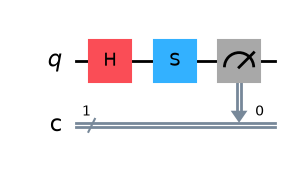

In [24]:
qc = QuantumCircuit(1,1)

qc.h(0)      # create superposition
qc.s(0)      # apply phase gate

qc.measure(0,0)

qc.draw('mpl')

{'1': 530, '0': 494}


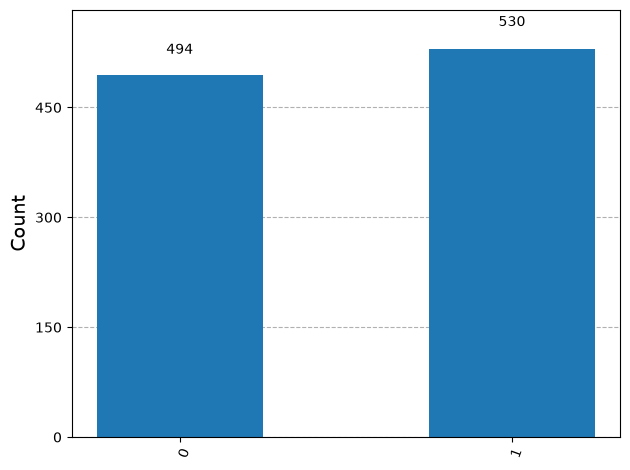

In [25]:
compiled = transpile(qc, simulator)

result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()

print(counts)

plot_histogram(counts)

**Bloch sphere view of a general phase rotation (P-gate)**

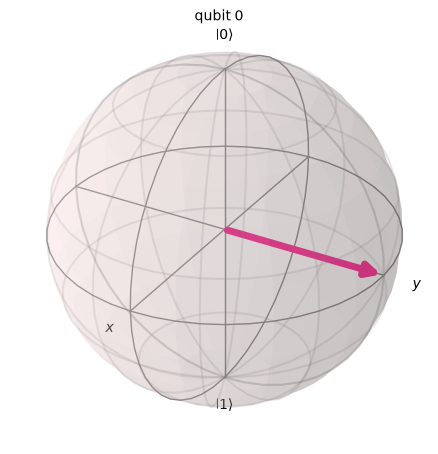

In [26]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector
import numpy as np

# create quantum circuit
qc = QuantumCircuit(1)

qc.rx(np.pi / 2, 0)      # rotation around X-axis
qc.p(np.pi, 0)           # phase gate

# save the statevector
qc.save_statevector()

# run simulator
sim = Aer.get_backend('aer_simulator')
result = sim.run(qc).result()

# extract final state
final_state = result.get_statevector()

# visualize on Bloch sphere
plot_bloch_multivector(final_state)


> **Exercise 6**. Change the above code so the final state is along the $x$-axis.

### T Gate

The **T gate** is another phase gate that introduces a **45° phase shift** to the |1⟩ state — half of what S does.

The matrix representation of the T gate is:

T =

[ 1    0 ]
[ 0  e^(iπ/4) ]

State transformation:

|0⟩ → |0⟩  
|1⟩ → e^(iπ/4)|1⟩

Similar to the Phase (S) gate, the T gate does **not change the measurement probability directly**.  
Instead, it changes the **phase of the quantum state**.

Continuing the pattern from S: T is the square root of S, and the fourth root of Z ($T^2 = S$, $T^4 = Z$) — you'll verify both identities directly in the exercises below. That fine-grained control over phase (45° increments instead of just 90° or 180°) is exactly why the T gate matters: together with H and the Pauli/Clifford gates, {H, S, T} form a **universal gate set** — any single-qubit operation can be approximated arbitrarily well using only these. (In real, error-corrected quantum hardware, T gates are also notoriously the most *expensive* operation to implement reliably — a detail that drives a lot of algorithm-design decisions in practice.)

To observe its effect, we first create **superposition** using the Hadamard gate — for the same reason as S and Z: applied to a bare |0⟩, T's phase shift would be invisible to measurement.

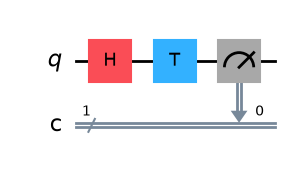

In [27]:
qc = QuantumCircuit(1,1)

qc.h(0)      # create superposition
qc.t(0)      # apply T gate

qc.measure(0,0)

qc.draw('mpl')

{'0': 503, '1': 521}


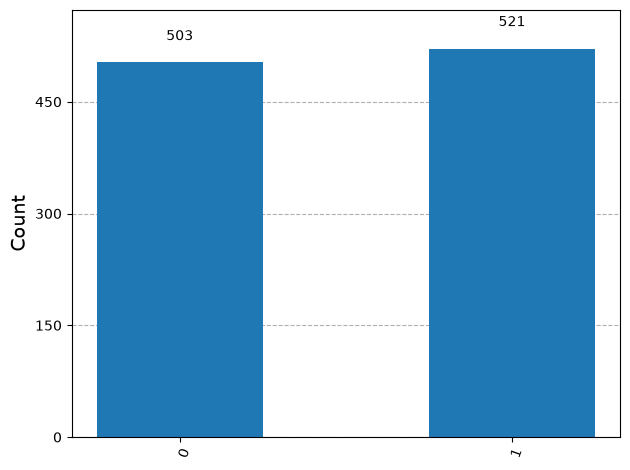

In [28]:
compiled = transpile(qc, simulator)

result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()

print(counts)

plot_histogram(counts)

### Try It Yourself

Modify the circuit and observe the results.

1. Apply **two T gates**

   T(T(|ψ⟩)) = ?

2. Apply **four T gates**

   What gate does this become equivalent to?

3. Try the sequence:

   H → T → H

   Explain the measurement result.

> **Note:** T, S, and Z only add *phase* — they never change the measurement probabilities of a qubit that is purely |0⟩ or |1⟩. To actually *see* their effect on measurement counts, the qubit must be in superposition (via H) and later recombined (via another H), so the phase gets converted into a probability difference through interference. Questions 1–2 below verify the gate identities directly using `Operator`; question 3 shows the interference effect using measurement counts.

T . T == S ? True


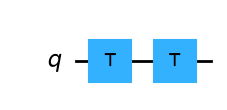

In [29]:
from qiskit.quantum_info import Operator
from qiskit.circuit.library import SGate

# 1. T . T  should equal the S gate
tt = QuantumCircuit(1)
tt.t(0)
tt.t(0)

print("T . T == S ?", Operator(tt).equiv(Operator(SGate())))
tt.draw('mpl')

T^4 == Z ? True


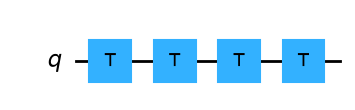

In [30]:
from qiskit.circuit.library import ZGate

# 2. T . T . T . T  should equal the Z gate
tttt = QuantumCircuit(1)
for _ in range(4):
    tttt.t(0)

print("T^4 == Z ?", Operator(tttt).equiv(Operator(ZGate())))
tttt.draw('mpl')

**3. H → T → H**

Unlike questions 1–2, this sequence changes measurement probabilities, because the T gate's phase is applied *while the qubit is in superposition*, and the second H converts that phase difference back into a probability difference (interference).

Working it out: starting from |0⟩,

- After H: (|0⟩ + |1⟩)/√2
- After T: (|0⟩ + e^(iπ/4)|1⟩)/√2
- After the second H, the amplitudes interfere, giving

  P(0) = (2 + √2) / 4 ≈ **85.4%**  
  P(1) = (2 − √2) / 4 ≈ **14.6%**

So instead of a flat 50/50 split (plain H) or a deterministic 0 (plain T on |0⟩), the H→T→H sequence should measure roughly an 85/15 split. This is the key idea behind phase gates: they are invisible on their own, but they bias outcomes once combined with interference — exactly how quantum algorithms extract useful answers from superposition.

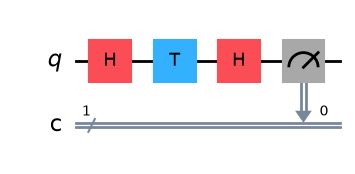

In [31]:
qc = QuantumCircuit(1,1)

qc.h(0)
qc.t(0)
qc.h(0)
qc.measure(0,0)

qc.draw('mpl')

{'1': 148, '0': 876}


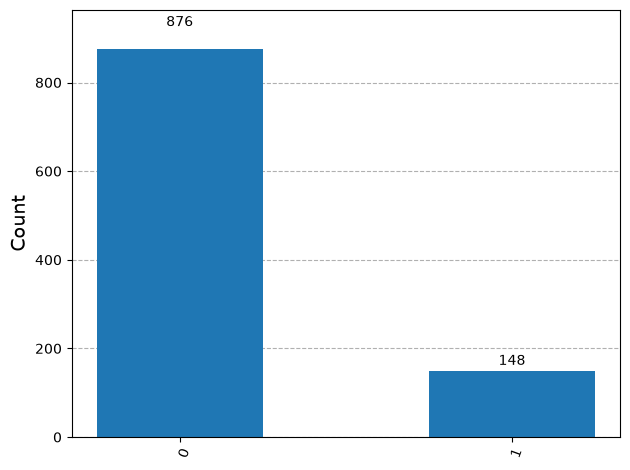

In [32]:
compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()
print(counts)   # expect roughly {'0': ~875, '1': ~150}, i.e. ~85/15, not 50/50

plot_histogram(counts)

## **Summary**

In this session, we have reviewed single qubit operations. They are important because of universality: given all possible one qubit operations and an entangling two qubit operation (see next session), we can build any circuit we want. We do not need $3, 4, 5, \ldots$ qubit gates at all.

It is also important to notice that any given quantum computer has a small number of gates available that the hardware uses. All other gates are reduced to those gates. For this reason, this small set is called the **physical gates**. For instance, the IBM quantum computer hardware uses the $X, SX, R_z$ and the $I$ gate. The latter is identity, a no operation gate.

In the next session we will focus on two qubit gates.

| Gate | Matrix | Effect |
|---|---|---|
| X (NOT) | [[0,1],[1,0]] | Flips \|0⟩ ↔ \|1⟩ |
| Y | [[0,−i],[i,0]] | Bit flip + phase flip |
| Z | [[1,0],[0,−1]] | Flips the sign of \|1⟩ only |
| H (Hadamard) | (1/√2)[[1,1],[1,−1]] | Creates superposition |
| S (Phase) | [[1,0],[0,i]] | 90° phase shift on \|1⟩; S = T² |
| T | [[1,0],[0,e^(iπ/4)]] | 45° phase shift on \|1⟩; T⁴ = Z |

**Key takeaway:** X, Y, and H change measurement *probabilities* directly. Z, S, and T only change *phase* — invisible in a single measurement, but they bias outcomes once combined with a second Hadamard (interference), as shown in the H→T→H exercise. This distinction between "probability" and "phase" is central to how quantum algorithms (e.g. Grover's search, the quantum Fourier transform) get their speedups.


# Student Challenge Section

The following exercises are designed to help you practice writing and modifying
quantum circuits using **Qiskit**.

Complete the code cells below. Each challenge requires you to think about
how quantum gates affect qubits and how measurement results change.



## Challenge 1: Create a Superposition

Objective:

Create a circuit with **one qubit** and apply a **Hadamard gate** to place the
qubit into a superposition state.

Steps:

1. Create a quantum circuit with 1 qubit.
2. Apply a Hadamard gate.
3. Measure the qubit.
4. Run the simulation.
5. Display the histogram.


In [33]:
# Write your solution below

from qiskit import QuantumCircuit

# Create circuit



# Apply Hadamard gate



# Measure



# Draw circuit




## Challenge 2: Apply Multiple Quantum Gates

Objective:

Modify the circuit so that it contains **two different quantum gates**.

Example ideas:

• Apply an **X gate followed by H gate**
• Apply **H then Z gate**

Observe how the output probabilities change.


In [34]:
# Write your solution below

# Create circuit



# Apply gates



# Measure and run simulation



In [35]:
# Write your solution below





# Documentation Requirements

Prepare a **PDF report** that documents your experiment.

Your report must contain the following sections.

## 1. Front Page

Include:

• Course Title  
• Laboratory Title  
• Student Name  
• Section  
• Instructor  
• Date

## 2. Introduction

Explain briefly:

• What quantum computing is  
• What Qiskit is  
• The objective of the experiment

## 3. Methodology

Describe:

• The quantum circuit you designed  
• The quantum gates used  
• The procedure followed

## 4. Source Code

Include the **complete Python code** used in the experiment.

## 5. Sample Run

Include screenshots showing:

• Circuit diagram  
• Histogram output  
• Simulation results

## 6. Discussion

Explain what happened in your experiment.

For example:

• Why did the probabilities change?  
• What effect did the gates have?

## 7. Conclusion

Summarize the main learning points of the experiment.

---

# Submission Instructions

Submit the following files to **Canvas**:

1. **PDF Documentation**
2. **Source Code (.ipynb file)**

### File Naming Format

Lastname_Firstname_QuantumLab1.pdf

